# World Model — Dataset 01: EDA & Audit (Báo cáo tuần 2)

**Áp dụng cho:** `~/nav_ws/wm_restore/wm_episode_batch/generated/dataset01/` (SocNavGym, batch 01). Notebook này **chỉ đánh giá dữ liệu**, không train model, không sửa hoặc ghi vào các tệp dataset gốc.

**Câu hỏi cần trả lời:** (1) Dữ liệu có bao nhiêu episode/window, chia split như thế nào? (2) Các modality có đủ lịch sử nhân quả? (3) Action tiến/lùi/chờ có phổ biến không? (4) Con người có thực sự di chuyển? (5) BEV target có bao nhiêu vùng quan sát được và ô có vật cản? (6) Thiếu gì để nghiên cứu *action-conditioned interaction effect*?

**Nguyên tắc:**
- Chỉ dùng **train + validation** để EDA chi tiết trên dữ liệu theo window. **Test chỉ xem metadata tổng hợp**, không mở `*_LABEL_ONLY` test và không xem ảnh test nhằm hạn chế leakage.
- `SENSOR_ONLY` là quan sát được dùng làm input; `LABEL_ONLY` là ground truth hoặc dữ liệu huấn luyện theo điều kiện, **không tự động là dữ liệu robot quan sát được**.
- `human_valid` là độ hợp lệ nội suy GT, **không phải nhãn nhìn thấy người**. Nhãn H1–H5 / track association / reward hiện chưa hợp lệ.
- Các cửa sổ chồng lấn nên **không coi các window là mẫu độc lập**. Phân bố lệnh được tính bằng timestamp query duy nhất **theo từng episode**.
- Dataset này chỉ có action đã được thực thi theo Nav2; không có các nhánh can thiệp tiến/lùi/chờ tái chạy từ cùng snapshot. Không suy ra nhân quả chỉ từ tương quan.

**Đầu ra:** CSV, hình PNG, báo cáo Markdown và JSON trong `~/nav_ws/wm_restore/wm_week2_reports/`.

## 0. Cài thư viện nếu thiếu

Trong terminal với đúng Python kernel của Jupyter:
```bash
python3 -m pip install numpy pandas matplotlib jupyterlab ipykernel
```
Trên Ubuntu có PEP 668, nên ưu tiên tạo `venv` rồi đăng ký kernel thay vì cài lên system Python:
```bash
cd ~/nav_ws
python3 -m venv .venv-wm-eda
source .venv-wm-eda/bin/activate
python -m pip install numpy pandas matplotlib jupyterlab ipykernel
python -m ipykernel install --user --name wm-eda --display-name "WM EDA"
jupyter lab
```
Chọn kernel **WM EDA**. Không cần ROS/Gazebo/GPU để chạy notebook.

In [3]:
from pathlib import Path
import json, warnings
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

DATA_ROOT = Path.home() / 'nav_ws/wm_restore/wm_episode_batch/generated/dataset01'
OUT = Path.home() / 'nav_ws/wm_restore/wm_week2_reports'
# Chỉ đổi hai đường dẫn ở trên nếu cài ở máy khác.
assert DATA_ROOT.is_dir(), f'Không thấy dataset: {DATA_ROOT}'
assert (DATA_ROOT / 'dataset.json').is_file(), 'Thiếu dataset.json'
OUT.mkdir(parents=True, exist_ok=True)

meta = json.loads((DATA_ROOT / 'dataset.json').read_text(encoding='utf-8'))
episodes = meta['episodes']
print('DATA_ROOT:', DATA_ROOT)
print('OUT:', OUT)
print('Schema:', meta.get('schema'))
print('Episodes accepted:', len(episodes), '| planned:', meta.get('planned_episodes'))
print('Các split:', Counter(e['split'] for e in episodes))
print('Test holdout: CHỈ metadata; không đọc sample/label test.')

def save_table(df, name):
    p = OUT / name
    df.to_csv(p, index=False, encoding='utf-8-sig')
    return p

def save_fig(name):
    plt.tight_layout()
    plt.savefig(OUT/name, dpi=175, bbox_inches='tight')
    plt.show()
    plt.close()

def pct(a):
    a = np.asarray(a)
    return (100 * float(np.mean(a))) if a.size else np.nan

DATA_ROOT: /home/haduckien/nav_ws/wm_restore/wm_episode_batch/generated/dataset01
OUT: /home/haduckien/nav_ws/wm_restore/wm_week2_reports
Schema: wm_sensor_action_dataset/1
Episodes accepted: 8 | planned: 10
Các split: Counter({'train': 5, 'validation': 2, 'test': 1})
Test holdout: CHỈ metadata; không đọc sample/label test.


## 1. Dataset manifest — phân bố split và tình trạng episode

Tách **cửa sổ đã xuất** khỏi **cửa sổ hợp lệ cho WM BEV**. Tập được chia theo **seed family**; validation/test không đồng nghĩa với môi trường/human policy chưa thấy.

,episode_id,scenario,seed,family,split,windows,wm_bev_valid_windows,wm_bev_invalid_windows,nav2_status,actual_goal_reached,raw_depth_frames,coverage_0p5_pct,coverage_1_pct,coverage_3_pct
0,wm_standing_45,standing,45,seed_45,train,851,851,0,TIMEOUT,False,1038,25.735090,25.624208,24.793614
1,wm_walking_45,walking,45,seed_45,train,597,597,0,SUCCEEDED,True,789,24.571834,24.396069,22.094890
2,wm_standing_46,standing,46,seed_46,train,259,259,0,SUCCEEDED,False,448,26.252187,26.168953,25.468486
3,wm_walking_46,walking,46,seed_46,train,268,268,0,SUCCEEDED,True,451,26.483245,26.353887,25.599056
4,wm_walking_47,walking,47,seed_47,train,800,788,12,TIMEOUT,False,1037,22.946808,22.742554,20.867950
5,wm_standing_48,standing,48,seed_48,validation,802,802,0,TIMEOUT,False,1040,23.103892,23.015094,22.396402
6,wm_walking_48,walking,48,seed_48,validation,850,850,0,TIMEOUT,False,1036,19.529211,19.319652,17.667567
7,wm_standing_49,standing,49,seed_49,test,679,679,0,SUCCEEDED,True,857,24.286958,24.176825,23.415531


Đã lưu: /home/haduckien/nav_ws/wm_restore/wm_week2_reports/01_episode_inventory.csv


,split,episodes,windows,wm_bev_valid,invalid
0,train,5,2775,2763,12
1,validation,2,1652,1652,0
2,test,1,679,679,0


Đã lưu: /home/haduckien/nav_ws/wm_restore/wm_week2_reports/02_split_summary.csv


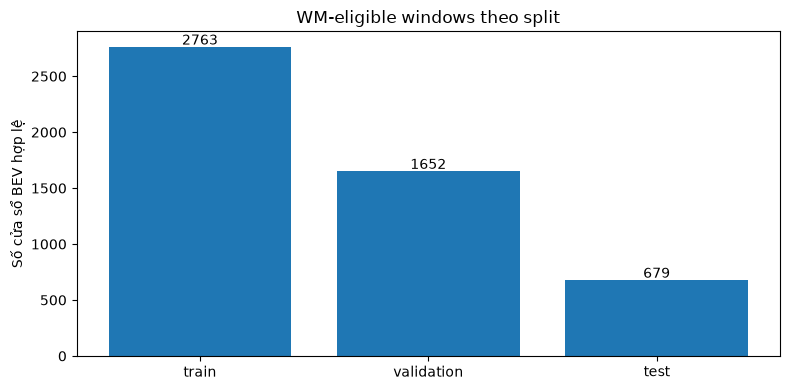

In [4]:
episode_df = pd.DataFrame([{
    'episode_id': e['episode_id'], 'scenario': e['scenario'], 'seed': e['seed'],
    'family': e.get('family'), 'split': e['split'],
    'windows': int(e['windows']),
    'wm_bev_valid_windows': int(e['wm_observed_bev_eligible_windows']),
    'wm_bev_invalid_windows': int(e['windows']) - int(e['wm_observed_bev_eligible_windows']),
    'nav2_status': e.get('navigation_status'), 'actual_goal_reached': e.get('actual_goal_reached'),
    'raw_depth_frames': e.get('raw_depth_frames'),
    'coverage_0p5_pct': 100 * e['observed_target_fraction'][0],
    'coverage_1_pct': 100 * e['observed_target_fraction'][1],
    'coverage_3_pct': 100 * e['observed_target_fraction'][2],
} for e in episodes])
display(episode_df)
print('Đã lưu:', save_table(episode_df, '01_episode_inventory.csv'))

split_df = (episode_df.groupby('split',sort=False)
            .agg(episodes=('episode_id','nunique'),
                 windows=('windows','sum'),wm_bev_valid=('wm_bev_valid_windows','sum'),
                 invalid=('wm_bev_invalid_windows','sum'))
            .reset_index())
order = {'train':0, 'validation':1, 'test':2}
split_df = split_df.sort_values('split',key=lambda s:s.map(order).fillna(99)).reset_index(drop=True)
display(split_df)
print('Đã lưu:', save_table(split_df, '02_split_summary.csv'))

fig,ax=plt.subplots(figsize=(8,4))
ax.bar(split_df['split'],split_df['wm_bev_valid'])
ax.set(ylabel='Số cửa sổ BEV hợp lệ',title='WM-eligible windows theo split')
for i,v in enumerate(split_df['wm_bev_valid']):ax.text(i,v+20,str(v),ha='center')
save_fig('01_split_window_counts.png')

## 2. Tự kiểm tra schema / shape thực tế (chỉ trên một episode train)

Đây là phần để trình thầy mô hình nhận **gì** và dự báo **gì**. `depth_SENSOR_ONLY.npy` được mở **memory-map**, không nạp toàn bộ ảnh depth nhiều GB vào RAM.

In [5]:
train_eps = [e for e in episodes if e['split'] == 'train']
val_eps = [e for e in episodes if e['split'] == 'validation']
analysis_eps = train_eps + val_eps
assert train_eps, 'Không có episode train'
SAMPLE_ID = train_eps[0]['episode_id']
sample_dir = DATA_ROOT / 'episodes' / SAMPLE_ID
schema_rows=[]
for rel in [
    'inputs/samples_SENSOR_ONLY.npz',
    'inputs/bev_anchor_estimated_SENSOR_ONLY.npz',
    'inputs/observations_SENSOR_ONLY.npz',
    'inputs/depth_SENSOR_ONLY.npy',
    'labels/future_trajectories_actions_LABEL_ONLY.npz',
    'labels/future_observed_bev_LABEL_ONLY.npz',
    'labels/task_masks_LABEL_ONLY.npz',
]:
    p = sample_dir/rel
    if not p.exists():
        warnings.warn(f'Missing file: {p}')
        continue
    if p.suffix=='.npy':
        arr=np.load(p,mmap_mode='r',allow_pickle=False)
        schema_rows.append({'file':rel,'key':'(array)','shape':str(arr.shape),'dtype':str(arr.dtype)})
        del arr
    else:
        with np.load(p,allow_pickle=False) as z:
            for key in z.files:
                arr=z[key]
                schema_rows.append({'file':rel,'key':key,'shape':str(arr.shape),'dtype':str(arr.dtype)})
schema_df=pd.DataFrame(schema_rows)
display(schema_df)
print('Schema:',save_table(schema_df,'03_npz_schema.csv'))

,file,key,shape,dtype
0,inputs/samples_SENSOR_ONLY.npz,anchor_ns,"(851,)",int64
1,inputs/samples_SENSOR_ONLY.npz,history_query_ns,"(851, 20)",int64
2,inputs/samples_SENSOR_ONLY.npz,scan_stamp_ns,"(851, 20)",int64
3,inputs/samples_SENSOR_ONLY.npz,scan_available_ns,"(851, 20)",int64
4,inputs/samples_SENSOR_ONLY.npz,scan_valid,"(851, 20)",bool
...,...,...,...,...
87,labels/task_masks_LABEL_ONLY.npz,executed_action_condition_valid,"(851,)",bool
88,labels/task_masks_LABEL_ONLY.npz,m1_track_aligned_valid,"(851, 30, 6)",bool
89,labels/task_masks_LABEL_ONLY.npz,persona_valid,"(851, 6)",bool
90,labels/task_masks_LABEL_ONLY.npz,rl_reward_valid,"(851,)",bool


Schema: /home/haduckien/nav_ws/wm_restore/wm_week2_reports/03_npz_schema.csv


## 3. Kiểm tra chất lượng và **tính nhân quả của lịch sử**

Với `history_query_ns[t]`, các phép đo được sử dụng trong lịch sử cần có `stamp_ns <= query_ns` **và** `available_ns <= query_ns` (trong các vị trí có validity mask). Đồng thời xem tỷ lệ mask hợp lệ cho từng modality. Đây là kiểm tra hợp đồng dữ liệu, không phải đo latency thiết bị ngoài đời.

,episode_id,split,scenario,windows,scan_history_valid_pct,scan_median_stamp_age_ms,imu_history_valid_pct,imu_median_stamp_age_ms,odom_history_valid_pct,odom_median_stamp_age_ms,action_history_valid_pct,action_median_stamp_age_ms,depth_history_valid_pct,depth_median_stamp_age_ms,lidar_ray_valid_pct,goal_valid_pct
0,wm_standing_45,train,standing,851,100.0,150.0,100.0,0.0,100.0,15.0,100.0,25.0,100.0,100.0,35.716,76.263
1,wm_walking_45,train,walking,597,100.0,150.0,100.0,0.0,100.0,15.0,100.0,25.0,100.0,100.0,33.406,96.315
2,wm_standing_46,train,standing,259,100.0,150.0,100.0,0.0,100.0,15.0,100.0,25.0,100.0,100.0,34.929,100.000
3,wm_walking_46,train,walking,268,100.0,150.0,100.0,0.0,100.0,15.0,100.0,25.0,100.0,100.0,17.537,100.000
4,wm_walking_47,train,walking,800,100.0,150.0,100.0,0.0,100.0,15.0,100.0,25.0,100.0,100.0,35.637,71.500
5,wm_standing_48,validation,standing,802,100.0,150.0,100.0,0.0,100.0,15.0,100.0,22.5,100.0,100.0,38.995,74.688
6,wm_walking_48,validation,walking,850,100.0,150.0,100.0,0.0,100.0,15.0,100.0,25.0,100.0,100.0,26.659,68.000


,episode_id,split,scenario,num_windows,history_steps,anchor_unique,anchor_monotonic,history_query_end_is_anchor,history_query_step_ms_median,history_span_s,scan_causality_violations,imu_causality_violations,odom_causality_violations,action_causality_violations,depth_causality_violations
0,wm_standing_45,train,standing,851,20,True,True,True,100.0,1.9,0,0,0,0,0
1,wm_walking_45,train,walking,597,20,True,True,True,100.0,1.9,0,0,0,0,0
2,wm_standing_46,train,standing,259,20,True,True,True,100.0,1.9,0,0,0,0,0
3,wm_walking_46,train,walking,268,20,True,True,True,100.0,1.9,0,0,0,0,0
4,wm_walking_47,train,walking,800,20,True,True,True,100.0,1.9,0,0,0,0,0
5,wm_standing_48,validation,standing,802,20,True,True,True,100.0,1.9,0,0,0,0,0
6,wm_walking_48,validation,walking,850,20,True,True,True,100.0,1.9,0,0,0,0,0


/home/haduckien/nav_ws/wm_restore/wm_week2_reports/04_sensor_quality.csv
/home/haduckien/nav_ws/wm_restore/wm_week2_reports/05_input_integrity.csv


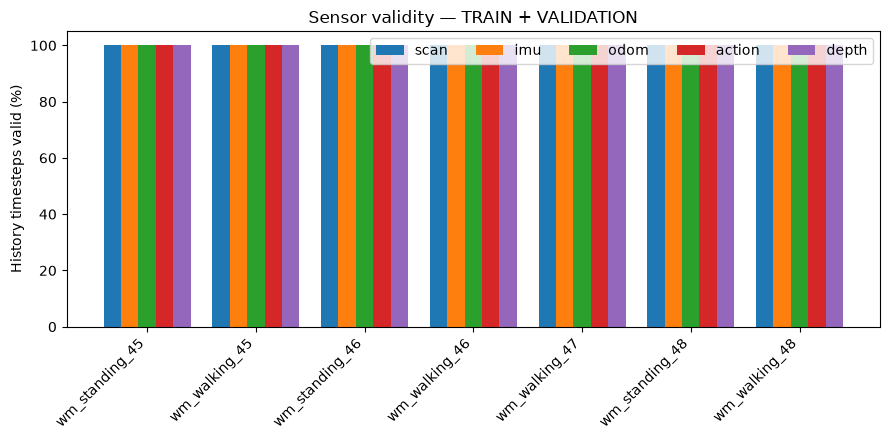

In [6]:
sensor_rows=[]; integrity_rows=[]
for ep in analysis_eps:
    eid=ep['episode_id']; root=DATA_ROOT/'episodes'/eid
    p=root/'inputs/samples_SENSOR_ONLY.npz'
    if not p.exists():
        warnings.warn(f'{eid}: thiếu {p.name}')
        continue
    with np.load(p,allow_pickle=False) as z:
        q=z['history_query_ns']
        a=z['anchor_ns']
        out={'episode_id':eid,'split':ep['split'],'scenario':ep['scenario'],
             'num_windows':len(a),'history_steps':q.shape[1],
             'anchor_unique':len(np.unique(a))==len(a),
             'anchor_monotonic':bool(np.all(np.diff(a)>0)),
             'history_query_end_is_anchor':bool(np.all(q[:,-1]==a)),
             'history_query_step_ms_median':float(np.median(np.diff(q,axis=1))/1e6),
             'history_span_s':float(np.median((q[:,-1]-q[:,0])/1e9))}
        s={'episode_id':eid,'split':ep['split'],'scenario':ep['scenario'],'windows':len(a)}
        for m in ('scan','imu','odom','action','depth'):
            valid=z[f'{m}_valid'].astype(bool)
            st=z[f'{m}_stamp_ns']; av=z[f'{m}_available_ns']
            s[m+'_history_valid_pct']=pct(valid)
            out[m+'_causality_violations']=int(np.sum(valid & ((st>q)|(av>q))))
            if valid.any():
                age=(q-st)/1e6
                s[m+'_median_stamp_age_ms']=float(np.median(age[valid]))
        if 'scan_ray_valid' in z:
            s['lidar_ray_valid_pct']=pct(z['scan_ray_valid'])
        if 'goal_valid' in z:
            s['goal_valid_pct']=pct(z['goal_valid'])
        sensor_rows.append(s)
        integrity_rows.append(out)
sensor_df=pd.DataFrame(sensor_rows); integrity_df=pd.DataFrame(integrity_rows)
display(sensor_df.round(3))
display(integrity_df)
print(save_table(sensor_df,'04_sensor_quality.csv'))
print(save_table(integrity_df,'05_input_integrity.csv'))

modals=['scan','imu','odom','action','depth']
fig,ax=plt.subplots(figsize=(9,4.5))
x=np.arange(len(sensor_df)); w=0.16
for j,m in enumerate(modals):
    ax.bar(x+(j-2)*w,sensor_df[m+'_history_valid_pct'],w,label=m)
ax.set_xticks(x,[str(v) for v in sensor_df['episode_id']],rotation=45,ha='right')
ax.set_ylim(0,105)
ax.set_ylabel('History timesteps valid (%)');ax.set_title('Sensor validity — TRAIN + VALIDATION')
ax.legend(ncol=5)
save_fig('02_sensor_validity.png')

## 4. Kiểm tra nhãn task, validity và thiếu supervision

Lưu ý: `m1_track_aligned_valid=False`, `persona_valid=False`, `rl_reward_valid=False` có nghĩa **chưa có nhãn hợp lệ**, không có nghĩa cảnh không có người hoặc reward bằng 0.

In [7]:
mask_rows=[]; warnings_list=[]
for ep in analysis_eps:
    eid=ep['episode_id']; label=DATA_ROOT/'episodes'/eid/'labels'
    p=label/'task_masks_LABEL_ONLY.npz'
    if not p.is_file():warnings_list.append(f'{eid}: missing task masks');continue
    with np.load(p,allow_pickle=False) as z:
        item={'episode_id':eid,'split':ep['split'],'scenario':ep['scenario']}
        for k in z.files:
            v=z[k]
            if np.issubdtype(v.dtype,np.bool_):item[k+'_true']=int(np.count_nonzero(v));item[k+'_total']=v.size
            elif np.issubdtype(v.dtype,np.floating):item[k+'_finite']=int(np.count_nonzero(np.isfinite(v)))
        mask_rows.append(item)
mask_df=pd.DataFrame(mask_rows)
display(mask_df)
print(save_table(mask_df,'06_task_mask_audit.csv'))
for m in ('m1_track_aligned_valid','persona_valid','rl_reward_valid'):
    key=m+'_true'
    if key in mask_df and int(mask_df[key].sum())==0:
        print('CHƯA ĐƯỢC GIÁM SÁT:',m)

,episode_id,split,scenario,wm_observed_bev_train_valid_true,wm_observed_bev_train_valid_total,executed_action_condition_valid_true,executed_action_condition_valid_total,m1_track_aligned_valid_true,m1_track_aligned_valid_total,persona_valid_true,persona_valid_total,rl_reward_valid_true,rl_reward_valid_total,rl_reward_finite
0,wm_standing_45,train,standing,851,851,851,851,0,153180,0,5106,0,851,0
1,wm_walking_45,train,walking,597,597,597,597,0,107460,0,3582,0,597,0
2,wm_standing_46,train,standing,259,259,259,259,0,46620,0,1554,0,259,0
3,wm_walking_46,train,walking,268,268,268,268,0,48240,0,1608,0,268,0
4,wm_walking_47,train,walking,788,800,800,800,0,144000,0,4800,0,800,0
5,wm_standing_48,validation,standing,802,802,802,802,0,144360,0,4812,0,802,0
6,wm_walking_48,validation,walking,850,850,850,850,0,153000,0,5100,0,850,0


/home/haduckien/nav_ws/wm_restore/wm_week2_reports/06_task_mask_audit.csv
CHƯA ĐƯỢC GIÁM SÁT: m1_track_aligned_valid
CHƯA ĐƯỢC GIÁM SÁT: persona_valid
CHƯA ĐƯỢC GIÁM SÁT: rl_reward_valid


## 5. Phân bố hành động robot — **khử trùng lặp rolling windows**

Từ `executed_action_query_ns` và `executed_action_future`. Đếm 1 hành động cho 1 **query timestamp / episode**, không đếm số lần timestamp xuất hiện trong các window chồng lấn.

Các tỷ lệ **forward/reverse/lateral/turn** là các thuộc tính **có thể đồng thời xảy ra**, nên tổng có thể vượt 100%. `stationary` là điều kiện cả ba thành phần vận tốc gần 0. Ngưỡng (`0.05 m/s`, `0.10 rad/s`) chỉ là ngưỡng thống kê đề xuất, **không phải nhãn hành vi chuẩn**.

,episode_id,split,scenario,unique_query_timestamps,removed_window_duplicates,inconsistent_duplicated_queries,vx_median_mps,vy_median_mps,wz_median_radps,forward_pct,reverse_pct,lateral_pct,rotate_pct,stationary_pct
0,wm_standing_45,train,standing,880,24650,0,0.027,0.017,0.001,39.091,0.795,41.705,36.364,37.273
1,wm_walking_45,train,walking,626,17284,0,0.017,0.056,-0.118,42.652,20.128,60.224,64.058,3.994
2,wm_standing_46,train,standing,288,7482,0,0.271,0.166,0.003,100.000,0.000,98.264,20.139,0.000
3,wm_walking_46,train,walking,297,7743,0,0.264,0.161,-0.043,100.000,0.000,100.000,23.906,0.000
4,wm_walking_47,train,walking,858,23142,0,0.011,-0.001,-0.022,33.333,7.459,38.462,37.529,45.105
5,wm_standing_48,validation,standing,860,23200,0,0.010,0.001,0.003,34.186,0.116,35.930,33.372,40.581
6,wm_walking_48,validation,walking,879,24621,0,0.024,0.011,0.005,47.440,3.982,53.811,26.962,40.728


/home/haduckien/nav_ws/wm_restore/wm_week2_reports/07_action_coverage_by_episode.csv


,split,unique_actions,forward_pct,reverse_pct,lateral_pct,rotate_pct,stationary_pct
0,train,2949,50.25,6.68,56.09,39.74,25.09
1,validation,1739,40.89,2.07,44.97,30.13,40.66


/home/haduckien/nav_ws/wm_restore/wm_week2_reports/08_action_coverage_by_split.csv


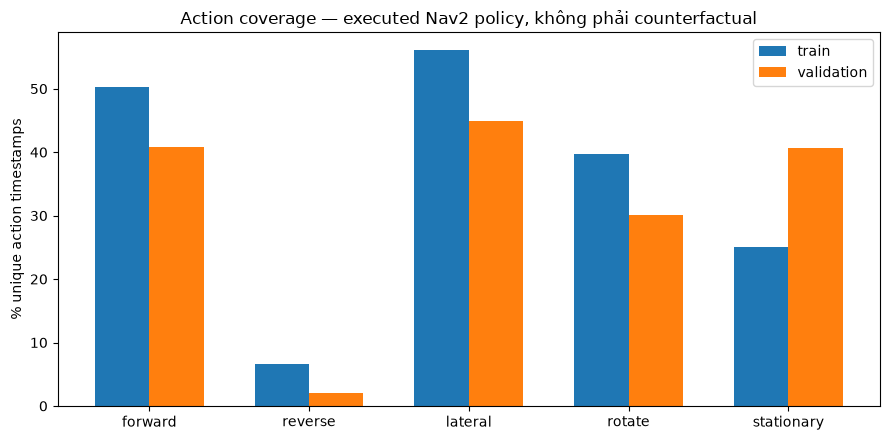

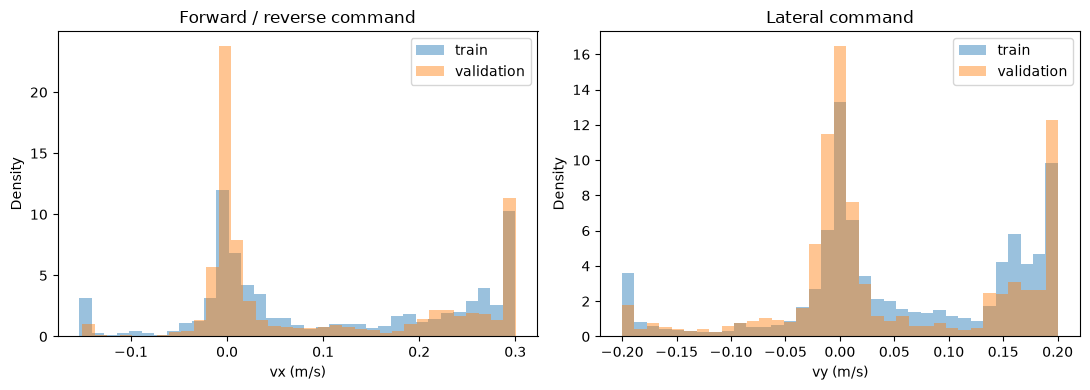

In [8]:
VX_TH=0.05   # m/s
VY_TH=0.05   # m/s
WZ_TH=0.10   # rad/s

def action_flags(a):
    vx,vy,wz=a[:,0],a[:,1],a[:,2]
    return {
        'forward':vx>VX_TH,
        'reverse':vx<-VX_TH,
        'lateral':np.abs(vy)>VY_TH,
        'rotate':np.abs(wz)>WZ_TH,
        'stationary':(np.abs(vx)<=VX_TH)&(np.abs(vy)<=VY_TH)&(np.abs(wz)<=WZ_TH),
    }

def unique_commands(z, good):
    t=z['executed_action_query_ns'][good].reshape(-1)
    a=z['executed_action_future'][good].reshape(-1,3)
    assert len(t)==len(a)
    if len(t)==0:return np.empty((0,3),np.float32),0,0
    ix=np.argsort(t,kind='stable'); ts=t[ix]; aa=a[ix]
    uniq,starts,counts=np.unique(ts,return_index=True,return_counts=True)
    hi=np.maximum.reduceat(aa,starts,axis=0)
    lo=np.minimum.reduceat(aa,starts,axis=0)
    inconsistent=int(np.sum(np.any(np.abs(hi-lo)>1e-3,axis=1)))
    return aa[starts],len(t)-len(uniq),inconsistent

action_rows=[]; action_long=[]; action_samples=defaultdict(list)
for ep in analysis_eps:
    eid=ep['episode_id']; lab=DATA_ROOT/'episodes'/eid/'labels'
    fp=lab/'future_trajectories_actions_LABEL_ONLY.npz'; mp=lab/'task_masks_LABEL_ONLY.npz'
    if not fp.is_file() or not mp.is_file():
        warnings_list.append(f'{eid}: missing action files');continue
    with np.load(fp,allow_pickle=False) as z, np.load(mp,allow_pickle=False) as m:
        good=m['executed_action_condition_valid'].astype(bool)
        a,repeat,conflicts=unique_commands(z,good)
    if not len(a):continue
    flags=action_flags(a)
    row={'episode_id':eid,'split':ep['split'],'scenario':ep['scenario'],
         'unique_query_timestamps':len(a),'removed_window_duplicates':repeat,
         'inconsistent_duplicated_queries':conflicts,
         'vx_median_mps':float(np.median(a[:,0])),
         'vy_median_mps':float(np.median(a[:,1])),
         'wz_median_radps':float(np.median(a[:,2]))}
    row.update({k+'_pct':pct(v) for k,v in flags.items()})
    action_rows.append(row)
    action_samples[ep['split']].append(a)
    action_long.extend([{'episode_id':eid,'split':ep['split'],'action_kind':k,'percent':pct(v)} for k,v in flags.items()])
action_df=pd.DataFrame(action_rows)
assert not action_df.empty, 'Không có action data cho train/validation'
display(action_df.round(3))
print(save_table(action_df,'07_action_coverage_by_episode.csv'))
if (action_df['inconsistent_duplicated_queries']>0).any():
    warnings_list.append('Có query timestamp trùng nhưng giá trị action khác nhau — cần kiểm tra normalizer!')

agg=[]
for split, blocks in action_samples.items():
    arr=np.concatenate(blocks,axis=0)
    item={'split':split,'unique_actions':len(arr)}
    item.update({k+'_pct':pct(v) for k,v in action_flags(arr).items()})
    agg.append(item)
action_agg=pd.DataFrame(agg)
display(action_agg.round(2))
print(save_table(action_agg,'08_action_coverage_by_split.csv'))

names=['forward','reverse','lateral','rotate','stationary']
fig,ax=plt.subplots(figsize=(9,4.5))
x=np.arange(len(names)); w=0.34
for j,(_,row) in enumerate(action_agg.iterrows()):
    ax.bar(x+(j-(len(action_agg)-1)/2)*w,
           [row[n+'_pct'] for n in names],width=w,label=row['split'])
ax.set_xticks(x,names);ax.set_ylabel('% unique action timestamps')
ax.set_title('Action coverage — executed Nav2 policy, không phải counterfactual')
ax.legend();save_fig('03_action_coverage.png')

fig,axs=plt.subplots(1,2,figsize=(11,4))
for split, blocks in action_samples.items():
    arr=np.concatenate(blocks,axis=0)
    axs[0].hist(arr[:,0],bins=35,density=True,alpha=0.45,label=split)
    axs[1].hist(arr[:,1],bins=35,density=True,alpha=0.45,label=split)
axs[0].set(xlabel='vx (m/s)',title='Forward / reverse command')
axs[1].set(xlabel='vy (m/s)',title='Lateral command')
for ax in axs:ax.set_ylabel('Density');ax.legend()
save_fig('04_action_histograms.png')

## 6. Phân bố chuyển động người — từ **GT simulator**, không phải detector

Tính vận tốc xấp xỉ giữa hai **anchor liên tiếp** (`human_xy_at_anchor_m`). Có kiểm tra `human_valid` và dt; không gán nhãn H1–H5. `standing/walking` là scenario khởi đầu, **không khẳng định người giữ trạng thái đó suốt episode**. Ngưỡng <0.1 m/s chỉ là gần như đứng yên ở mức quan sát.

,episode_id,scenario,split,speed_valid_pairs,speed_median_mps,speed_p90_mps,near_standing_speed_below_0p1_pct,gt_human_3s_pairs,gt_3s_displacement_median_m,gt_3s_displacement_p90_m
0,wm_standing_45,standing,train,5100,0.342,1.275,22.980,5106,0.000,1.794
1,wm_walking_45,walking,train,3576,0.553,1.816,2.209,3582,0.938,1.877
2,wm_standing_46,standing,train,1548,0.342,0.692,3.941,1554,0.175,1.976
3,wm_walking_46,walking,train,1602,0.641,1.139,0.187,1608,1.351,1.842
4,wm_walking_47,walking,train,4788,0.607,2.894,12.364,4800,0.000,2.050
5,wm_standing_48,standing,validation,4800,0.232,0.688,31.667,4812,0.000,1.676
6,wm_walking_48,walking,validation,5094,0.347,1.204,21.044,5100,0.000,1.843


/home/haduckien/nav_ws/wm_restore/wm_week2_reports/09_human_gt_motion.csv


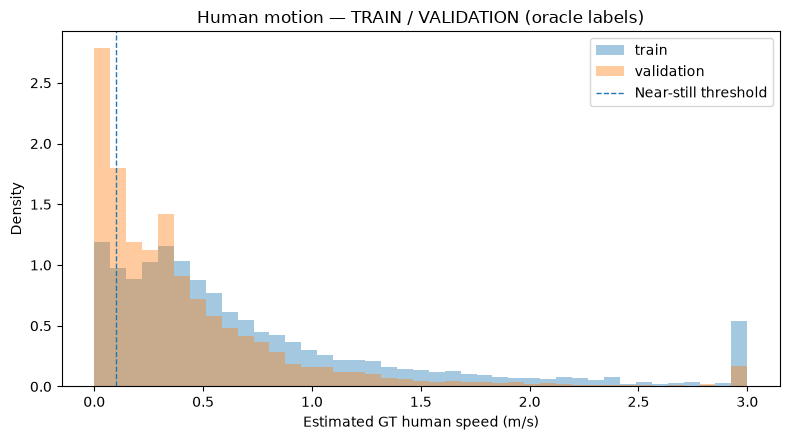

In [9]:
human_rows=[]; human_speed_samples=defaultdict(list); human_displacement_samples=defaultdict(list)
for ep in analysis_eps:
    eid=ep['episode_id']; root=DATA_ROOT/'episodes'/eid
    fp=root/'labels/future_trajectories_actions_LABEL_ONLY.npz'
    ip=root/'inputs/samples_SENSOR_ONLY.npz'
    if not fp.is_file() or not ip.is_file():warnings_list.append(f'{eid}: missing human data');continue
    with np.load(fp,allow_pickle=False) as z, np.load(ip,allow_pickle=False) as s:
        xy=z['human_xy_at_anchor_m']; support=z['human_valid'][:,0,:]
        time=s['anchor_ns'].astype(np.float64)/1e9
        assert len(time)==len(xy)
        dt=np.diff(time)
        finite=np.isfinite(xy).all(axis=2)
        valid=(support[1:] & support[:-1] & finite[1:] & finite[:-1]
              & (dt[:,None]>0) & (dt[:,None]<=0.25))
        speed=np.linalg.norm(np.diff(xy,axis=0),axis=-1)/np.maximum(dt[:,None],1e-9)
        speeds=speed[valid]
        last_valid=z['human_valid'][:,-1,:] & finite & np.isfinite(z['human_xy_future_m'][:,-1,:,:]).all(axis=2)
        disp=np.linalg.norm(z['human_xy_future_m'][:,-1,:,:]-xy,axis=-1)[last_valid]
    human_speed_samples[ep['split']].append(speeds)
    human_displacement_samples[ep['split']].append(disp)
    human_rows.append({'episode_id':eid,'scenario':ep['scenario'],'split':ep['split'],
        'speed_valid_pairs':len(speeds),
        'speed_median_mps':float(np.median(speeds)) if len(speeds) else np.nan,
        'speed_p90_mps':float(np.quantile(speeds,.9)) if len(speeds) else np.nan,
        'near_standing_speed_below_0p1_pct':pct(speeds<0.1),
        'gt_human_3s_pairs':len(disp),
        'gt_3s_displacement_median_m':float(np.median(disp)) if len(disp) else np.nan,
        'gt_3s_displacement_p90_m':float(np.quantile(disp,.9)) if len(disp) else np.nan})
human_df=pd.DataFrame(human_rows)
display(human_df.round(3))
print(save_table(human_df,'09_human_gt_motion.csv'))

fig,ax=plt.subplots(figsize=(8,4.5))
for split, blocks in human_speed_samples.items():
    s=np.concatenate(blocks)
    if len(s):ax.hist(np.clip(s,0,3),bins=np.linspace(0,3,42),density=True,alpha=.4,label=split)
ax.axvline(.1,ls='--',lw=1,label='Near-still threshold')
ax.set(xlabel='Estimated GT human speed (m/s)',ylabel='Density',title='Human motion — TRAIN / VALIDATION (oracle labels)')
ax.legend();save_fig('05_human_gt_speed.png')

## 7. BEV target: unknown / free / occupied, theo horizon

`occupancy` = -1 (unknown), 0 (observed free), 1 (occupied). Chỉ đo `occupied_pct_given_observed` **trong những ô `cell_loss_valid`**. Phải loại unknown khỏi loss. Đây là **BEV thực sự quan sát được từ depth tương lai**, không phải occupancy toàn thế giới.

,episode_id,scenario,split,horizon_s,eligible_windows,cell_valid_count,eligible_cell_count,observed_valid_pct_of_all_cells,occupied_pct_given_valid_observed,mask_unknown_inconsistency_count
0,wm_standing_45,standing,train,0.5,851,897047,3485696,25.735,5.566,0
1,wm_standing_45,standing,train,1.0,851,893182,3485696,25.624,5.518,0
2,wm_standing_45,standing,train,3.0,851,864230,3485696,24.794,5.445,0
3,wm_walking_45,walking,train,0.5,597,600858,2445312,24.572,4.695,0
4,wm_walking_45,walking,train,1.0,597,596560,2445312,24.396,4.712,0
5,wm_walking_45,walking,train,3.0,597,540289,2445312,22.095,4.617,0
6,wm_standing_46,standing,train,0.5,259,278500,1060864,26.252,4.265,0
7,wm_standing_46,standing,train,1.0,259,277617,1060864,26.169,4.119,0
8,wm_standing_46,standing,train,3.0,259,270186,1060864,25.468,3.728,0
9,wm_walking_46,walking,train,0.5,268,290714,1097728,26.483,2.422,0


/home/haduckien/nav_ws/wm_restore/wm_week2_reports/10_bev_coverage_occupancy.csv


,split,horizon_s,observed,total,observed_pct
0,train,0.5,2807584,11317248,24.808010
1,train,1.0,2791493,11317248,24.665829
2,train,3.0,2639514,11317248,23.322932
3,validation,0.5,1438890,6766592,21.264619
4,validation,1.0,1428677,6766592,21.113686
5,validation,3.0,1350834,6766592,19.963284


/home/haduckien/nav_ws/wm_restore/wm_week2_reports/11_bev_coverage_by_split_horizon.csv


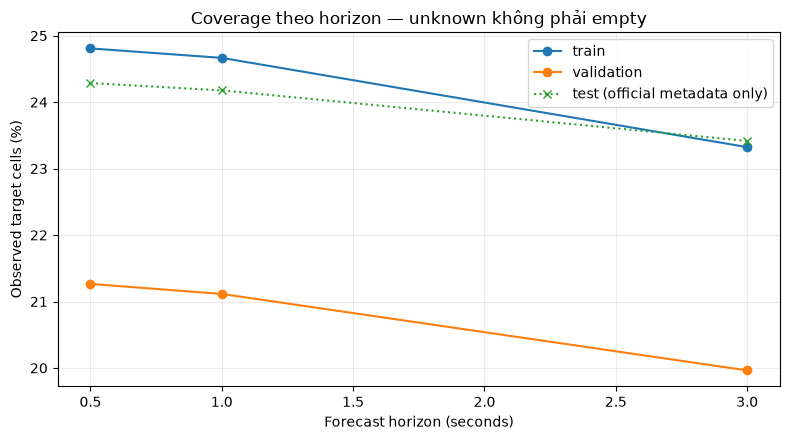

In [10]:
bev_rows=[]; hs=(.5,1,3)
for ep in analysis_eps:
    eid=ep['episode_id']; root=DATA_ROOT/'episodes'/eid/'labels'
    p=root/'future_observed_bev_LABEL_ONLY.npz'; m=root/'task_masks_LABEL_ONLY.npz'
    if not p.is_file() or not m.is_file():warnings_list.append(f'{eid}: missing BEV target');continue
    with np.load(p,allow_pickle=False) as z, np.load(m,allow_pickle=False) as masks:
        occ=z['occupancy']; valid=z['cell_loss_valid'].astype(bool)
        eligible=masks['wm_observed_bev_train_valid'].astype(bool)
        assert occ.ndim==4 and len(occ)==len(eligible)
        for j,h in enumerate(hs):
            sel=eligible[:,None,None]&valid[:,j]
            observed=(occ[:,j]!=-1)
            count=int(np.count_nonzero(sel))
            num=int(np.count_nonzero(eligible))*occ.shape[2]*occ.shape[3]
            occupied=int(np.count_nonzero(sel & (occ[:,j]==1)))
            unknown_inside=int(np.count_nonzero(sel & ~observed))
            bev_rows.append({
                'episode_id':eid,'scenario':ep['scenario'],'split':ep['split'],'horizon_s':h,
                'eligible_windows':int(np.count_nonzero(eligible)),
                'cell_valid_count':count,'eligible_cell_count':num,
                'observed_valid_pct_of_all_cells':(100*count/num) if num else np.nan,
                'occupied_pct_given_valid_observed':(100*occupied/count) if count else np.nan,
                'mask_unknown_inconsistency_count':unknown_inside,
            })
bev_df=pd.DataFrame(bev_rows)
display(bev_df.round(3))
print(save_table(bev_df,'10_bev_coverage_occupancy.csv'))

bev_split=(bev_df.groupby(['split','horizon_s'],sort=False)
    .agg(observed=('cell_valid_count','sum'),total=('eligible_cell_count','sum'))
    .reset_index())
bev_split['observed_pct']=100*bev_split['observed']/bev_split['total']
display(bev_split)
print(save_table(bev_split,'11_bev_coverage_by_split_horizon.csv'))
fig,ax=plt.subplots(figsize=(8,4.5))
for split,d in bev_split.groupby('split'):
    ax.plot(d['horizon_s'],d['observed_pct'],marker='o',label=split)
# Test: chỉ từ metadata tổng hợp, KHÔNG đọc label arrays.
if (episode_df['split']=='test').any():
    for h,col in zip(hs,('coverage_0p5_pct','coverage_1_pct','coverage_3_pct')):
        pass
    t=episode_df[episode_df['split']=='test']
    weights=t['windows'].to_numpy(dtype=float)
    xx=[np.average(t[c].to_numpy(),weights=weights) for c in ('coverage_0p5_pct','coverage_1_pct','coverage_3_pct')]
    ax.plot(hs,xx,marker='x',linestyle=':',label='test (official metadata only)')
ax.set(xlabel='Forecast horizon (seconds)',ylabel='Observed target cells (%)',title='Coverage theo horizon — unknown không phải empty')
ax.legend();ax.grid(alpha=.25);save_fig('06_bev_coverage_by_horizon.png')

## 8. Trực quan hóa một window **train**: depth, BEV và quỹ đạo người GT

Hình tương lai là **nhãn ground truth**, tuyệt đối không chú thích là kết quả World Model. Ảnh depth chỉ đọc **một frame** từ file `.npy` bằng mmap. Trong trường hợp lỗi thiếu frame có thể chỉ xem BEV.

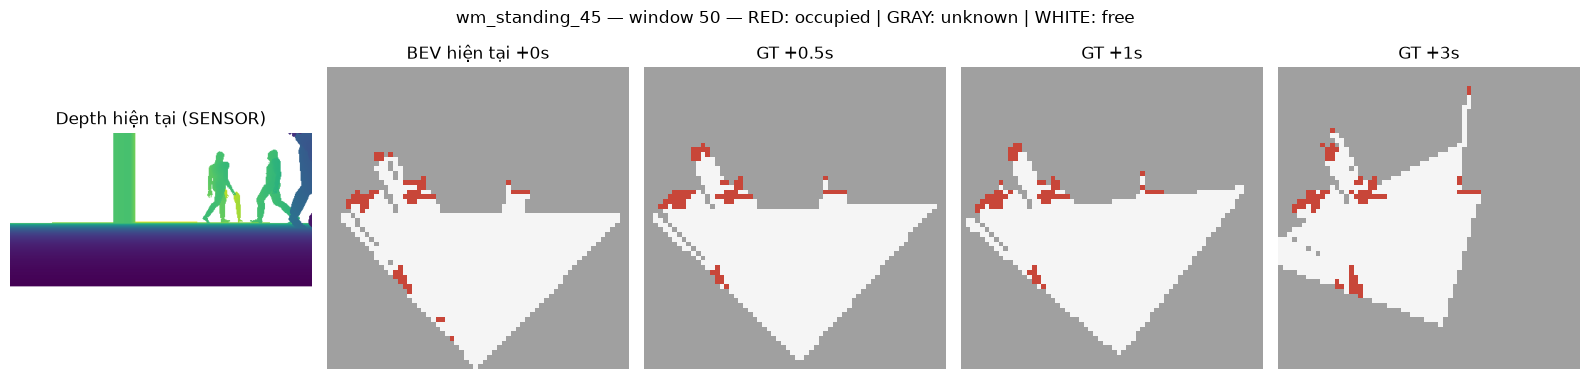

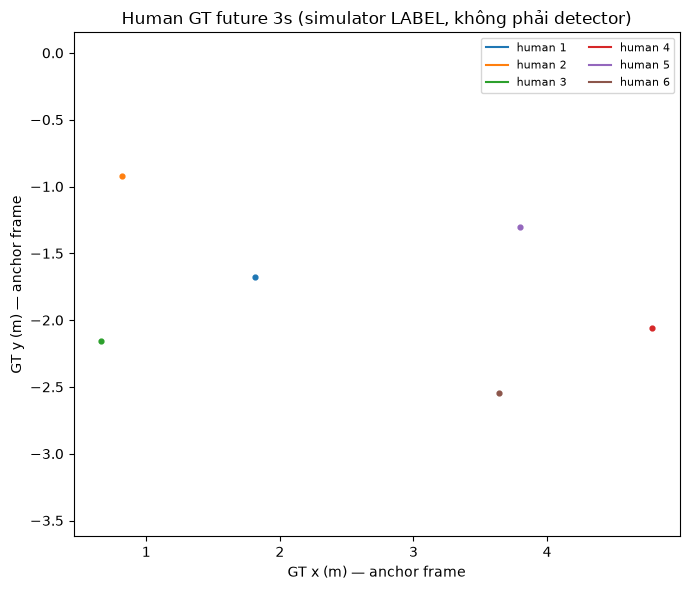

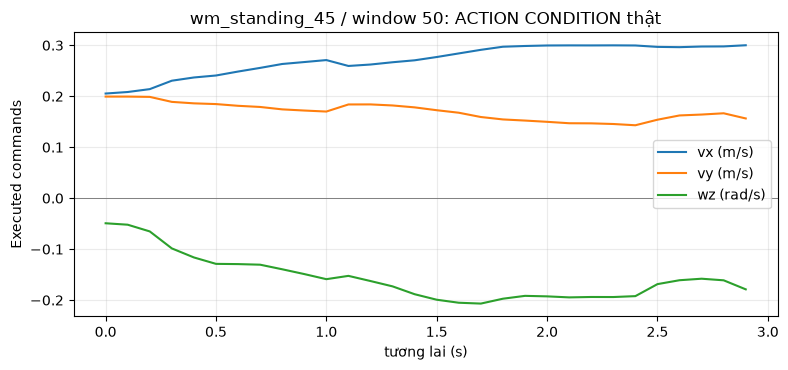

In [11]:
from matplotlib.colors import ListedColormap, BoundaryNorm
ex=DATA_ROOT/'episodes'/SAMPLE_ID
with np.load(ex/'inputs/samples_SENSOR_ONLY.npz',allow_pickle=False) as x:
    sample_idx=min(50,len(x['anchor_ns'])-1)
    depth_idx=int(x['depth_index'][sample_idx,-1])
with np.load(ex/'inputs/bev_anchor_estimated_SENSOR_ONLY.npz',allow_pickle=False) as inp:
    bev0=inp['occupancy'][sample_idx]
with np.load(ex/'labels/future_observed_bev_LABEL_ONLY.npz',allow_pickle=False) as out:
    future=out['occupancy'][sample_idx]
with np.load(ex/'labels/future_trajectories_actions_LABEL_ONLY.npz',allow_pickle=False) as lab:
    traj=lab['human_xy_future_m'][sample_idx].copy()
    human0=lab['human_xy_at_anchor_m'][sample_idx].copy()
    valid=lab['human_valid'][sample_idx].copy()
    actions=lab['executed_action_future'][sample_idx].copy()

# [-1,0,1] -> [0,1,2], rõ ràng unknown/free/occupied.
cmap=ListedColormap(['#a0a0a0','#f5f5f5','#c84639'])
norm=BoundaryNorm([-0.5,0.5,1.5,2.5],cmap.N)
fig,axes=plt.subplots(1,5,figsize=(16,4))
depthpath=ex/'inputs/depth_SENSOR_ONLY.npy'
if depthpath.exists():
    depth=np.load(depthpath,mmap_mode='r',allow_pickle=False)
    d=np.array(depth[depth_idx],dtype=np.float32)
    finite=np.isfinite(d)&(d>0)
    axes[0].imshow(np.where(finite,d,np.nan),cmap='viridis',vmin=.28,vmax=5)
    axes[0].set_title('Depth hiện tại (SENSOR)')
    del depth,d
else:
    axes[0].text(.5,.5,'Depth file missing',ha='center',va='center')
    axes[0].set_title('Depth không có')
for ax,array,title in zip(axes[1:], [bev0,*future], ['BEV hiện tại +0s','GT +0.5s','GT +1s','GT +3s']):
    ax.imshow(array.astype(int)+1,cmap=cmap,norm=norm,origin='lower')
    ax.set_title(title)
for ax in axes:ax.axis('off')
fig.suptitle(f'{SAMPLE_ID} — window {sample_idx} — RED: occupied | GRAY: unknown | WHITE: free')
save_fig('07_train_sample_depth_bev.png')

fig,ax=plt.subplots(figsize=(7,6))
for h in range(traj.shape[1]):
    ok=valid[:,h] & np.isfinite(traj[:,h,:]).all(axis=1)
    if not np.any(ok):continue
    ax.plot(traj[ok,h,0],traj[ok,h,1],lw=1.5,label=f'human {h+1}')
    ax.scatter(human0[h,0],human0[h,1],marker='o',s=12)
ax.set(xlabel='GT x (m) — anchor frame',ylabel='GT y (m) — anchor frame',
       title='Human GT future 3s (simulator LABEL, không phải detector)')
ax.set_aspect('equal',adjustable='datalim');ax.legend(fontsize=8,ncol=2)
save_fig('08_train_sample_gt_human_trajectories.png')

fig,ax=plt.subplots(figsize=(8,3.8))
t=np.arange(len(actions))*.1
for j,name in enumerate(['vx (m/s)','vy (m/s)','wz (rad/s)']):
    ax.plot(t,actions[:,j],label=name)
ax.set(xlabel='tương lai (s)',ylabel='Executed commands',title=f'{SAMPLE_ID} / window {sample_idx}: ACTION CONDITION thật')
ax.axhline(0,color='gray',lw=.7);ax.legend();ax.grid(alpha=.25)
save_fig('09_train_sample_executed_action.png')

## 9. Leakage, split, nhãn thiếu và những phát hiện cần báo cáo

Không dùng kết quả Nav2 SUCCEEDED như một ground-truth success tuyệt đối nếu `actual_goal_reached` mâu thuẫn. Kiểm tra tính độc lập **theo seed-family**, không phải theo từng window. Đừng khẳng định generalization sang warehouse/human-policy mới từ batch này.

In [12]:
checks=[]
def check(name,passed,detail):checks.append({'check':name,'passed':bool(passed),'detail':str(detail)})
seed_splits=episode_df.groupby('family')['split'].nunique()
check('Seed-family không xuyên split', bool((seed_splits<=1).all()),dict(seed_splits))
check('Đúng số episode accepted',len(episode_df)==int(meta.get('accepted_episodes',len(episode_df))),len(episode_df))
check('Train/validation cùng warehouse chưa phải OOD',False,meta.get('split_rule','N/A'))
check('Association labels có sẵn',bool(meta.get('association_valid',False)),meta.get('association_valid'))
check('Persona labels có sẵn',bool(meta.get('persona_valid',False)),meta.get('persona_valid'))
check('RL reward có sẵn',bool(meta.get('RL_reward_valid',False)),meta.get('RL_reward_valid'))
check('Can thiệp có đối chứng từ cùng snapshot',False,'Chưa có replay branch IDs / outcomes theo action trong schema dataset01')
check('Test có walking holdout',False,meta.get('test_coverage_limit','not specified'))
status_mismatch=episode_df[(episode_df['nav2_status']=='SUCCEEDED') & (~episode_df['actual_goal_reached'].astype(bool))]
check('Nav2 SUCCEEDED khớp actual_goal_reached',status_mismatch.empty,status_mismatch['episode_id'].tolist())
if 'inconsistent_duplicated_queries' in action_df:
    check('Trùng future query có cùng action',bool((action_df['inconsistent_duplicated_queries']==0).all()),
          int(action_df['inconsistent_duplicated_queries'].sum()))
causal_cols=[x for x in integrity_df if x.endswith('_causality_violations')]
check('Không dùng history sensor sau query',int(integrity_df[causal_cols].sum().sum())==0,
      int(integrity_df[causal_cols].sum().sum()))
check_df=pd.DataFrame(checks)
display(check_df)
print(save_table(check_df,'12_research_readiness_checks.csv'))
print('WARNING: False ở các check nghiên cứu là HẠN CHẾ chưa giải quyết, không có nghĩa dataset hỏng.')

,check,passed,detail
0,Seed-family không xuyên split,True,"{'seed_45': np.int64(1), 'seed_46': np.int64(1..."
1,Đúng số episode accepted,True,8
2,Train/validation cùng warehouse chưa phải OOD,False,Entire paired-seed family; no overlapping wind...
3,Association labels có sẵn,False,False
4,Persona labels có sẵn,False,False
5,RL reward có sẵn,False,False
6,Can thiệp có đối chứng từ cùng snapshot,False,Chưa có replay branch IDs / outcomes theo acti...
7,Test có walking holdout,False,Only standing49 accepted; walking49 quarantine...
8,Nav2 SUCCEEDED khớp actual_goal_reached,False,['wm_standing_46']
9,Trùng future query có cùng action,True,0


/home/haduckien/nav_ws/wm_restore/wm_week2_reports/12_research_readiness_checks.csv


## 10. Tổng hợp 1 trang cho slide và báo cáo tuần 2

Các giá trị dưới đây được lấy trực tiếp từ metadata và từ phép đo **train/validation** vừa chạy. Tuyệt đối không diễn giải masked GT là classifier/detector đã hoạt động hoặc kết quả action-effect nhân quả.

In [14]:
total=int(episode_df['windows'].sum())
valid_total=int(episode_df['wm_bev_valid_windows'].sum())
quarantined=meta.get('quarantined_episodes',[])
summary={
    'dataset_schema':meta.get('schema'),
    'accepted_episodes':len(episode_df),
    'quarantined_capture_count':len(quarantined),
    'exported_windows':total,
    'wm_bev_valid_windows':valid_total,
    'split_summary':split_df.to_dict(orient='records'),
    'action_coverage_trainval':action_agg.to_dict(orient='records'),
    'readiness':check_df.to_dict(orient='records'),
    'caveats':[
      'Test labels/imagery were not inspected during EDA',
      'Observed BEV is depth-derived partial occupancy; unknown != free',
      'Ground-truth human positions do not imply sensor association',
      'Nav2 executed commands are observational, not paired interventions',
      'Overlapping windows not independent; compare at episode/seed-family level',
    ]
}
(OUT/'13_summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2,default=str),encoding='utf-8')
train_line=action_agg[action_agg['split']=='train']
rev=float(train_line['reverse_pct'].iloc[0]) if 'reverse_pct' in train_line and len(train_line) else np.nan
lines=[
    '# Kết quả EDA dataset01 — World Model tuần 2',
    '',
    f'- Dataset: {len(episode_df)} episode được chấp nhận; {len(quarantined)} raw capture cách ly.',
    f'- Cửa sổ xuất: {total}; cửa sổ WM observed-BEV hợp lệ: {valid_total}.',
    f'- Test coverage: {meta.get("test_coverage_limit", "N/A")}.',
    f'- Train: {len(train_eps)} episode; Validation: {len(val_eps)} episode.',
    f'- Tỷ lệ query action có vx < -{VX_TH} m/s (train): {rev:.2f}% (đã khử chồng lấn theo timestamp / episode).',
    '- BEV future ở +0.5/+1/+3s: unknown phải được masked, không là free.',
    '- Nhãn vị trí người GT chỉ dành phân tích, chưa có association từ depth/LiDAR.',
    '- Chưa đủ paired intervention để đo action-effect causal/contrafactual.',
    '- Chưa đánh giá mô hình, ADE/FDE hay navigation improvement trong notebook này.',
    '',
    '## Việc đề xuất tuần 3',
    '1. Dùng observed-BEV hợp lệ để chạy baseline prediction trên train/validation, không mở test trước khi chốt.',
    '2. Thu cùng snapshot với tiến/chờ/lùi và đối chứng seed, human-policy, geometry.',
    '3. Đo reaction-effect error và so sánh action-aware với action-agnostic WM sau khi có branches.',
    '4. Báo cáo hạn chế seed/scene, không tuyên bố unseen-environment generalization.',
    '',
    '## Files tạo ra',
    *[f'- {p.name}' for p in sorted(OUT.iterdir()) if p.suffix in ('.csv','.png','.json')]
]
(OUT/'14_report_week2.md').write_text('\n'.join(lines)+'\n',encoding='utf-8')
print('\n'.join(lines[:16])); print('\nXuất báo cáo:', OUT/'14_report_week2.md')

# Kết quả EDA dataset01 — World Model tuần 2

- Dataset: 8 episode được chấp nhận; 2 raw capture cách ly.
- Cửa sổ xuất: 5106; cửa sổ WM observed-BEV hợp lệ: 5094.
- Test coverage: Only standing49 accepted; walking49 quarantined, no held-out walking episode in this batch.
- Train: 5 episode; Validation: 2 episode.
- Tỷ lệ query action có vx < -0.05 m/s (train): 6.68% (đã khử chồng lấn theo timestamp / episode).
- BEV future ở +0.5/+1/+3s: unknown phải được masked, không là free.
- Nhãn vị trí người GT chỉ dành phân tích, chưa có association từ depth/LiDAR.
- Chưa đủ paired intervention để đo action-effect causal/contrafactual.
- Chưa đánh giá mô hình, ADE/FDE hay navigation improvement trong notebook này.

## Việc đề xuất tuần 3
1. Dùng observed-BEV hợp lệ để chạy baseline prediction trên train/validation, không mở test trước khi chốt.
2. Thu cùng snapshot với tiến/chờ/lùi và đối chứng seed, human-policy, geometry.
3. Đo reaction-effect error và so sánh action-aware với action-agnostic